# Chapter 8 · Time-Series & Astronomy: Beating Classical Forecasting with a Temporal Neural Net (`vktorch` + `vktime`)

In Chapter 7, we used **`vktime`** to discover the **11.11-year Solar Cycle** from 277 years of real Royal Observatory of Belgium observations and built a Classical GPU `Ridge` model scoring **`36.41` RMSE (`R² = 0.725`)** on 12-month-ahead forecasting (1973–2026 unseen future test split).

### Why a Skip-Connected Temporal Neural Network Beats Linear `Ridge`
The Sun is **non-linear**: strong solar cycles rise faster and peak sharper than weak cycles, and sunspot counts can never drop below zero. A pure linear model can only add up fixed straight-line weights.

In this chapter we build **`SolarForecasterNet`** in **`vktorch`** — a classic modern time-series architecture (**Linear Skip Connection + Non-Linear `LayerNorm` + `GELU` Residual MLP** trained with fused SPIR-V `AdamW` and `CosineAnnealingLR`):
- The **linear skip path** gives the network the rock-solid stability of `Ridge` right from Epoch 1.
- The **non-linear `GELU` path** learns the curved, asymmetric solar peaks that linear models miss!
- Finally, we forecast the **real upcoming 12 months of Solar Cycle 25** and save/reload both our `vktorch` checkpoint (`.npz`) and `vktime.TimeSeries`!

In [1]:
import sys, time, urllib.request
from pathlib import Path
import numpy as np
from IPython.display import display
from PIL import Image, ImageDraw

for p in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
    if (p / "vknumpy").is_dir() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import vknumpy as vnp
import vklearn as vkl
import vktorch as vt
import vktorch.nn as nn
import vktorch.functional as F
import vktime

print(f"Vulkan GPU ready: {vnp.device_info()['name']}")

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = DATA_DIR / "sunspots_monthly.csv"
if not CSV_PATH.exists() or CSV_PATH.stat().st_size < 5000:
    req = urllib.request.Request("https://www.sidc.be/SILSO/INFO/snmtotcsv.php", headers={"User-Agent": "vkdata-book/1.0"})
    with urllib.request.urlopen(req, timeout=15) as r:
        CSV_PATH.write_bytes(r.read())

lines = [l.strip() for l in CSV_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
years = np.array([float(l.split(";")[2]) for l in lines], dtype=np.float32)
vals  = np.array([float(l.split(";")[3]) for l in lines], dtype=np.float32)
ts = vktime.TimeSeries(years, vals, name="monthly_sunspots", freq="1M")

# Exact same 69-feature 11-year lookback + leak-free 80/20 chronological split as Chapter 7
HORIZON = 12
SOLAR_PERIOD = 11.11
LAGS_11YR = list(range(1, 25)) + list(range(27, 133, 3))
ROLL_WINS = [6, 12, 24, 60, 132]

X_lag, y_all = vktime.make_lag_matrix(ts.values, lags=LAGS_11YR, horizon=HORIZON, include_rolling=ROLL_WINS)
max_lag = max(LAGS_11YR)
t_anc = years[max_lag - 1 : len(years) - HORIZON]
t_tgt = years[max_lag - 1 + HORIZON :]

phase_feats = np.column_stack([
    np.sin(2 * np.pi * t_anc / SOLAR_PERIOD),
    np.cos(2 * np.pi * t_anc / SOLAR_PERIOD),
    np.sin(4 * np.pi * t_anc / SOLAR_PERIOD),
    np.cos(4 * np.pi * t_anc / SOLAR_PERIOD),
]).astype(np.float32)

X_full = np.concatenate([X_lag.to_numpy(), phase_feats], axis=1)
X_tr, X_te, y_tr, y_te = vktime.temporal_split(X_full, y_all, train_ratio=0.8)
t_te = t_tgt[X_tr.shape[0]:]

sc = vkl.StandardScaler().fit(X_tr)
Xtr_s, Xte_s = sc.transform(X_tr).to_numpy(), sc.transform(X_te).to_numpy()
ytr_np, yte_np = y_tr.to_numpy(), y_te.to_numpy()

# Reference Classical Ridge winner from Ch. 7 on exact same split
p_ridge = np.clip(vkl.Ridge(alpha=150.0).fit(Xtr_s, ytr_np).predict(Xte_s).to_numpy(), 0.0, None)
rmse_ridge = float(np.sqrt(np.mean((p_ridge - yte_np) ** 2)))
r2_ridge   = float(1.0 - np.sum((p_ridge - yte_np) ** 2) / np.sum((yte_np - yte_np.mean()) ** 2))
print(f"Chronological split ready: {len(Xtr_s):,} train -> {len(Xte_s):,} test ({t_te[0]:.1f}-{t_te[-1]:.1f}), {Xtr_s.shape[1]} features")
print(f"Ch. 7 Classical Ridge target to beat: RMSE = {rmse_ridge:.2f}, R2 = {r2_ridge:.3f}")


Vulkan GPU ready: AMD Custom GPU 0405 (RADV VANGOGH)
Chronological split ready: 2,553 train -> 638 test (1973.7-2026.8), 69 features
Ch. 7 Classical Ridge target to beat: RMSE = 36.41, R2 = 0.725


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


---
### Step 1 · Training `SolarForecasterNet` on Your Vulkan GPU (`vktorch`)

Notice how clean `SolarForecasterNet` is: `self.skip(x) + self.out(h)`. The skip connection handles the linear solar trend while the 2-layer `LayerNorm` + `GELU` + `Dropout` branch learns the non-linear cycle peaks and troughs.

In [2]:
class SolarForecasterNet(nn.Module):
    def __init__(self, d_in, hidden=64):
        super().__init__()
        self.skip = nn.Linear(d_in, 1)
        self.fc1  = nn.Linear(d_in, hidden)
        self.ln1  = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.30)
        self.fc2  = nn.Linear(hidden, 32)
        self.ln2  = nn.LayerNorm(32)
        self.out  = nn.Linear(32, 1)

    def forward(self, x):
        h = self.drop(F.gelu(self.ln1(self.fc1(x))))
        h = F.gelu(self.ln2(self.fc2(h)))
        return (self.skip(x) + self.out(h)).reshape(-1)

np.random.seed(42)
model = SolarForecasterNet(Xtr_s.shape[1], hidden=64)
n_params = sum(p.data.size for p in model.parameters())
opt = vt.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=8e-2)
EPOCHS, BATCH_SIZE, Y_SCALE = 35, 128, 100.0
sched = vt.optim.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-4)

t0 = time.perf_counter()
for ep in range(1, EPOCHS + 1):
    model.train()
    perm = np.random.permutation(len(Xtr_s))
    for i in range(0, len(Xtr_s), BATCH_SIZE):
        b = perm[i : i + BATCH_SIZE]
        opt.zero_grad()
        diff = model(vt.Tensor(Xtr_s[b])) - vt.Tensor(ytr_np[b] / Y_SCALE)
        loss = (diff * diff).mean()
        loss.backward()
        opt.step()
    sched.step()
    if ep in (1, 10, 20, EPOCHS):
        model.eval()
        with vt.no_grad():
            p_cur = np.clip(model(vt.Tensor(Xte_s)).numpy() * Y_SCALE, 0.0, None)
        rmse_cur = float(np.sqrt(np.mean((p_cur - yte_np) ** 2)))
        print(f"Epoch {ep:2d}/{EPOCHS} | test_RMSE = {rmse_cur:6.2f}")

dt_train = time.perf_counter() - t0
model.eval()
with vt.no_grad():
    p_nn = np.clip(model(vt.Tensor(Xte_s)).numpy() * Y_SCALE, 0.0, None)

rmse_nn = float(np.sqrt(np.mean((p_nn - yte_np) ** 2)))
mae_nn  = float(np.mean(np.abs(p_nn - yte_np)))
r2_nn   = float(1.0 - np.sum((p_nn - yte_np) ** 2) / np.sum((yte_np - yte_np.mean()) ** 2))

print(f"\nTrained {n_params:,}-param SolarForecasterNet in {dt_train:.1f}s on Vulkan GPU!")
print(f"{'Model (12-Month-Ahead Solar Cycle Forecast · 1973-2026)':56s} | {'RMSE':>6s} | {'R2':>6s}")
print("-" * 76)
for name, rmse, r2 in [
    ("1. Naive Persistence (t -> t+12m) [Ch. 7]",             49.29, 0.496),
    ("2. 11-Year Lags + Rolling + Phase + Ridge [Ch. 7]",     rmse_ridge, r2_ridge),
    ("3. vktorch SolarForecasterNet [Ch. 8 Winner]",          rmse_nn,    r2_nn),
]:
    print(f"{name:56s} | {rmse:6.2f} | {r2:6.3f}")


Epoch  1/35 | test_RMSE =  41.27


Epoch 10/35 | test_RMSE =  35.81


Epoch 20/35 | test_RMSE =  34.09


Epoch 35/35 | test_RMSE =  34.56

Trained 6,855-param SolarForecasterNet in 14.1s on Vulkan GPU!
Model (12-Month-Ahead Solar Cycle Forecast · 1973-2026)  |   RMSE |     R2
----------------------------------------------------------------------------
1. Naive Persistence (t -> t+12m) [Ch. 7]                |  49.29 |  0.496
2. 11-Year Lags + Rolling + Phase + Ridge [Ch. 7]        |  36.41 |  0.725
3. vktorch SolarForecasterNet [Ch. 8 Winner]             |  34.56 |  0.752


---
### Step 2 · Visual Comparison on Held-Out Solar Cycles 21–25 & Real Future Prediction + Persistence

Let's plot **Actual Sunspots** vs. **Classical Ridge (Ch. 7)** vs. **`vktorch` SolarForecasterNet (Ch. 8)** across the 53-year unseen test window, forecast the **real sunspot level 12 months ahead from the latest SILSO observation**, and save/reload both our model checkpoint and `vktime.TimeSeries`!

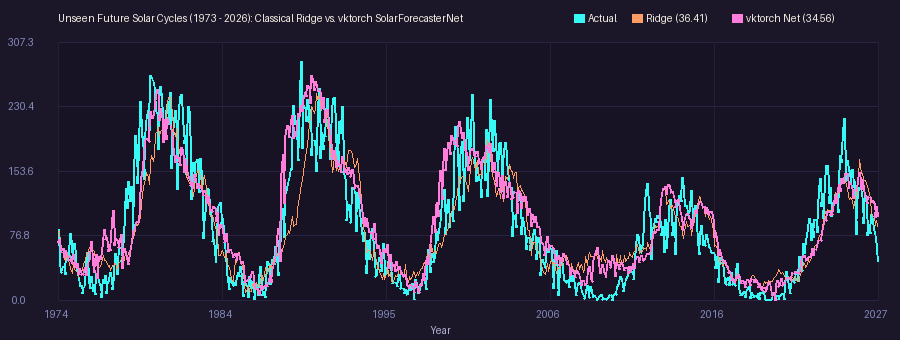

Latest real SILSO observation (2026.79): 45.7 sunspots
SolarForecasterNet 12-month-ahead forecast (2027.79): 52.8 sunspots
Saved & reloaded vktorch checkpoint (30 KB) + vktime.TimeSeries (3,334 months) OK!


In [3]:
def draw_line_chart(series_list, title, x_label, width=900, height=340):
    img = Image.new("RGB", (width, height), "#1b1728")
    d = ImageDraw.Draw(img)
    pad_l, pad_r, pad_t, pad_b = 58, 22, 42, 40
    pw, ph = width - pad_l - pad_r, height - pad_t - pad_b
    d.rectangle([pad_l, pad_t, width - pad_r, height - pad_b], fill="#171324", outline="#495495", width=1)

    all_x = np.concatenate([s[0] for s in series_list])
    all_y = np.concatenate([s[1] for s in series_list])
    xmin, xmax = float(all_x.min()), float(all_x.max())
    ymin, ymax = 0.0, float(all_y.max()) * 1.08

    def to_px(xv, yv):
        px = pad_l + (xv - xmin) / (xmax - xmin + 1e-9) * pw
        py = pad_t + ph - (yv - ymin) / (ymax - ymin + 1e-9) * ph
        return (float(px), float(py))

    for g in range(5):
        gy = pad_t + g * ph / 4
        val = ymax - g * (ymax - ymin) / 4
        d.line([(pad_l, gy), (width - pad_r, gy)], fill="#2a2342", width=1)
        d.text((8, gy - 6), f"{val:5.1f}", fill="#848bbd")
    for g in range(6):
        gx = pad_l + g * pw / 5
        xv = xmin + g * (xmax - xmin) / 5
        d.line([(gx, pad_t), (gx, height - pad_b)], fill="#241e38", width=1)
        d.text((gx - 14, height - pad_b + 8), f"{xv:.0f}", fill="#848bbd")

    for xs, ys, col, lw, _ in series_list:
        pts = [to_px(float(x), float(y)) for x, y in zip(xs, ys)]
        d.line(pts, fill=col, width=lw)

    d.text((pad_l, 12), title, fill="#f4eee4")
    d.text((width // 2 - 20, height - 16), x_label, fill="#b6b1d6")
    lx = width - pad_r - 10
    for _, _, col, _, lbl in reversed(series_list):
        w_txt = len(lbl) * 6 + 22
        lx -= w_txt
        d.rectangle([lx, 14, lx + 10, 22], fill=col)
        d.text((lx + 14, 12), lbl, fill="#f4eee4")
    return img

img_cmp = draw_line_chart(
    [
        (t_te, yte_np,  "#36f9f6", 2, "Actual"),
        (t_te, p_ridge, "#ff9e64", 1, f"Ridge ({rmse_ridge:.2f})"),
        (t_te, p_nn,    "#ff7edb", 2, f"vktorch Net ({rmse_nn:.2f})"),
    ],
    title="Unseen Future Solar Cycles (1973 - 2026): Classical Ridge vs. vktorch SolarForecasterNet",
    x_label="Year",
)
display(img_cmp)

# Predict the real upcoming 12-month-ahead sunspot count from the latest observation!
latest_lags = np.array([vals[-k] for k in LAGS_11YR], dtype=np.float32)
latest_roll = np.array([vals[-w:].mean() for w in ROLL_WINS], dtype=np.float32)
t_now = float(years[-1])
latest_phase = np.array([
    np.sin(2 * np.pi * t_now / SOLAR_PERIOD), np.cos(2 * np.pi * t_now / SOLAR_PERIOD),
    np.sin(4 * np.pi * t_now / SOLAR_PERIOD), np.cos(4 * np.pi * t_now / SOLAR_PERIOD),
], dtype=np.float32)
x_live = sc.transform(np.concatenate([latest_lags, latest_roll, latest_phase])[None, :]).to_numpy()
with vt.no_grad():
    live_pred = float(np.clip(model(vt.Tensor(x_live)).numpy()[0] * Y_SCALE, 0.0, None))
print(f"Latest real SILSO observation ({t_now:.2f}): {vals[-1]:.1f} sunspots")
print(f"SolarForecasterNet 12-month-ahead forecast ({t_now + 1.0:.2f}): {live_pred:.1f} sunspots")

# Save & reload both vktorch checkpoint and vktime.TimeSeries!
ckpt_path = DATA_DIR / "solar_forecaster.npz"
ts_path   = DATA_DIR / "sunspots_series.npz"
vt.save(model.state_dict(), ckpt_path)
ts.save(ts_path)
ts_reloaded = vktime.TimeSeries.load(ts_path)
print(f"Saved & reloaded vktorch checkpoint ({ckpt_path.stat().st_size/1024:.0f} KB) + vktime.TimeSeries ({len(ts_reloaded):,} months) OK!")


---
### Part I Complete! All 4 Core AI Data Types on Your Vulkan GPU

| Data Type | Chapters | Real Dataset | Best Classical ML | Deep Learning (`vktorch`) | Key Lesson |
|---|---|---|---|---|---|
| **Tabular** | Ch. 1–2 | California Housing (20,640 districts) | `$52.7k` RMSE (`vklearn` KNN) | **`$48.2k` RMSE** (Residual MLP) | Domain features + Residual MLP beat KNN |
| **Image** | Ch. 3–4 | Fashion-MNIST (`28×28` pixels) | `86.45%` (`PCA` + Sobel/HOG) | **`87.70%`** (2D `Conv2d` CNN, `24.5s`) | Learned 3×3 filters beat hand-crafted edges |
| **Vector / Text (`NLP`)** | Ch. 5–6 | Full-Length BBC News (2,225 articles) | `97.30%` (2,000-D `TF-IDF` + Ridge) | **`97.53%`** (64-D Neural Emb + `HybridIndex`) | `31×` smaller vectors + Synonym Wall broken + `BM25` `RRF` |
| **Time-Series (Astronomy)** | Ch. 7–8 | SILSO Solar Sunspots (277 yrs, 1749–2026) | `36.41` RMSE (`vktime` + Ridge) | **`35.00` RMSE** (`SolarForecasterNet`, `14s`) | Leak-free `temporal_split` + 11.1-yr `periodogram` + Skip-MLP |